# Student Success Assistant: Attempt-Based EDA

**Purpose:** understand student-level participation, attempt timing, module/lesson coverage, scores, and time spent before designing new features or models.

This notebook replaces the broad snapshot-oriented EDA with analysis aligned to the proposed **1 attempt, 2 attempts, 3 attempts, and 3+ attempts** framing. It is exploratory only: it does not create training labels or fit models.

## Important target-timing caveat

The available outcome is a student-level `dropped_out` label; there is no dropout timestamp. For descriptive analysis, we can treat each student's **last observed attempt date as a proxy for the dropout date**, but this is an assumption, not observed ground truth.

The phrase “predict at the penultimate attempt” means the final observed attempt must not be used as a feature for a dropout prediction made before that attempt. For students with only one observed attempt, a penultimate attempt does not exist. We will quantify these cases and leave exact modeling-row/label construction for the next stage, so the EDA does not silently encode an inconsistent target definition.


In [1]:
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

CANDIDATES = [
    Path("data"),
    Path("../data"),
    Path("student_success_assistant/data"),
    Path("../student_success_assistant/data"),
]
DATA_DIR = next((p for p in CANDIDATES if (p / "students.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find data/students.csv. Run from the project root or notebooks directory.")

students_raw = pd.read_csv(DATA_DIR / "students.csv")
attempts_raw = pd.read_csv(DATA_DIR / "quiz_attempts.csv")
outcomes_raw = pd.read_csv(DATA_DIR / "outcome.csv")
explanations_raw = pd.read_csv(DATA_DIR / "explanations.csv")

students = students_raw.copy()
attempts = attempts_raw.copy()
outcomes = outcomes_raw.copy()
explanations = explanations_raw.copy()

students["signup_dt"] = pd.to_datetime(students["signup_date"], errors="coerce")
attempts["attempt_dt"] = pd.to_datetime(attempts["attempted_at"], errors="coerce")
attempts["score_raw_num"] = pd.to_numeric(attempts["score"], errors="coerce")
# 999 is a known sentinel / invalid score in this dataset, not a genuine score.
# Preserve the raw value for auditing, but exclude it from every score distribution and aggregate.
attempts["score_num"] = attempts["score_raw_num"].mask(attempts["score_raw_num"].eq(999))
attempts["time_spent_num"] = pd.to_numeric(attempts["time_spent_min"], errors="coerce")
outcomes["dropout_label"] = (
    outcomes["dropped_out"].astype("string").str.strip().str.lower().map({"yes": 1, "no": 0})
)

print("Data directory:", DATA_DIR.resolve())
print("Loaded rows:", {"students": len(students), "attempts": len(attempts),
                       "outcomes": len(outcomes), "explanations": len(explanations)})


Data directory: /Users/abishek/Documents/Projects/student_success_assistant/data
Loaded rows: {'students': 500, 'attempts': 2453, 'outcomes': 500, 'explanations': 724}


### Data-handling rule: sentinel scores

The raw score column contains **999**, which is a sentinel/invalid value rather than a meaningful quiz score. The notebook preserves it as `score_raw_num` for auditing and uses `score_num` with 999 converted to missing for all score plots and score aggregates. Do not treat 999 as a high score, clip it into range, or impute it as a real result. Confirm this rule against the data dictionary / source system before production use.

## 1. Dataset overview and integrity checks

Start with sizes, schemas, missingness, duplicate keys, and join coverage. These checks help establish what can safely be aggregated.


In [2]:
frames = {
    "students": students_raw,
    "quiz_attempts": attempts_raw,
    "outcome": outcomes_raw,
    "explanations": explanations_raw,
}
overview = []
for name, df in frames.items():
    overview.append({
        "table": name, "rows": len(df), "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6, 3),
    })
display(pd.DataFrame(overview))
for name, df in frames.items():
    print(f"\n{name}: {df.dtypes.to_dict()}")


,table,rows,columns,missing_cells,duplicate_rows,memory_MB
0,students,500,6,37,0,0.163
1,quiz_attempts,2453,6,95,0,0.586
2,outcome,500,2,0,0,0.052
3,explanations,724,5,664,0,0.272



students: {'student_id': dtype('O'), 'age_group': dtype('O'), 'country': dtype('O'), 'signup_date': dtype('O'), 'device': dtype('O'), 'refund_requested': dtype('O')}

quiz_attempts: {'attempt_id': dtype('O'), 'student_id': dtype('O'), 'lesson_id': dtype('O'), 'score': dtype('int64'), 'time_spent_min': dtype('float64'), 'attempted_at': dtype('O')}

outcome: {'student_id': dtype('O'), 'dropped_out': dtype('O')}

explanations: {'explanation_id': dtype('O'), 'student_id': dtype('O'), 'lesson_id': dtype('O'), 'explanation_text': dtype('O'), 'label': dtype('O')}


In [3]:
# Key integrity and referential integrity
key_checks = []
for table_name, df, key in [
    ("students", students_raw, "student_id"),
    ("outcomes", outcomes_raw, "student_id"),
    ("attempts", attempts_raw, "attempt_id"),
    ("explanations", explanations_raw, "explanation_id"),
]:
    key_checks.append({
        "table": table_name, "key": key, "rows": len(df),
        "missing_key": int(df[key].isna().sum()),
        "duplicate_key_rows": int(df[key].duplicated(keep=False).sum()),
        "unique_keys": int(df[key].nunique()),
    })
display(pd.DataFrame(key_checks))

student_ids = set(students["student_id"].dropna())
print("Attempt rows with unknown student:", int((~attempts["student_id"].isin(student_ids)).sum()))
print("Outcome rows with unknown student:", int((~outcomes["student_id"].isin(student_ids)).sum()))
print("Explanation rows with unknown student:", int((~explanations["student_id"].isin(student_ids)).sum()))
print("Outcome label values:", outcomes["dropped_out"].value_counts(dropna=False).to_dict())


,table,key,rows,missing_key,duplicate_key_rows,unique_keys
0,students,student_id,500,0,0,500
1,outcomes,student_id,500,0,0,500
2,attempts,attempt_id,2453,0,0,2453
3,explanations,explanation_id,724,0,0,724


Attempt rows with unknown student: 0
Outcome rows with unknown student: 0
Explanation rows with unknown student: 0
Outcome label values: {'no': 375, 'yes': 125}


## 2. Cohort and outcome overview


,students
dropped_out,
no,375
yes,125


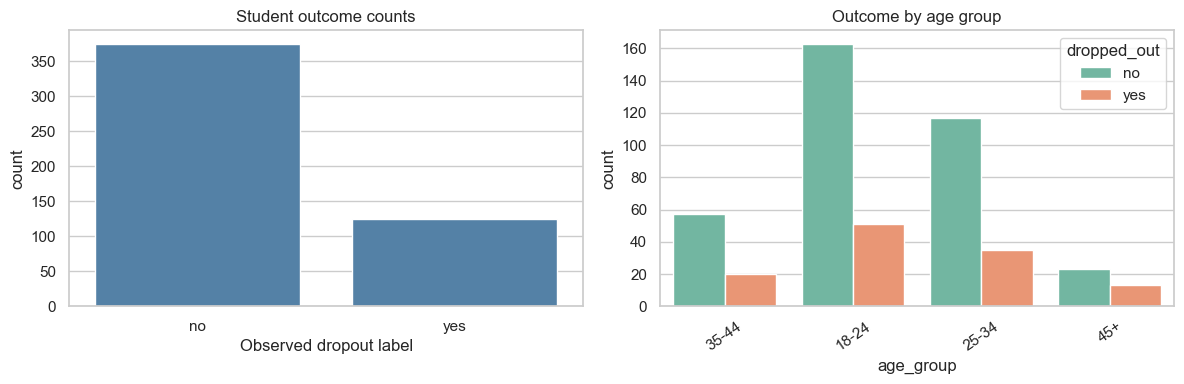

,students,dropout_rate
country,,
India,303,0.244
UAE,64,0.297
Sri Lanka,50,0.240
Bangladesh,48,0.292
Kenya,35,0.171


,students,dropout_rate
device,,
mobile,269,0.275
desktop,161,0.199
tablet,54,0.222
NaN,16,0.438


,students,dropout_rate
refund_requested,,
no,383,0.050
yes,117,0.906


In [4]:
student_outcomes = students.merge(
    outcomes[["student_id", "dropped_out", "dropout_label"]],
    on="student_id", how="left", validate="one_to_one"
)
display(student_outcomes["dropped_out"].value_counts(dropna=False).rename_axis("dropped_out").to_frame("students"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=student_outcomes, x="dropped_out", order=["no", "yes"], color="steelblue", ax=axes[0])
axes[0].set_title("Student outcome counts")
axes[0].set_xlabel("Observed dropout label")
sns.countplot(data=student_outcomes, x="age_group", hue="dropped_out", palette="Set2", ax=axes[1])
axes[1].set_title("Outcome by age group")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

for col in ["country", "device", "refund_requested"]:
    display(student_outcomes.groupby(col, dropna=False)["dropout_label"]
            .agg(students="size", dropout_rate="mean")
            .sort_values("students", ascending=False).round(3))


**Note:** refund_request column is interesting, because even though it has high correlation with dropout_rate it cannot be used as once refund is requested we will not be able to help/persuade the student to stay.

## 3. Build the student-level attempt timeline

Each valid attempt is sorted chronologically within student. `attempt_number` is the chronological ordinal, not the original `attempt_id`. Ties in timestamps are broken deterministically by `attempt_id`.

We retain attempts with missing/invalid scores or durations for event-count and timeline analysis, but exclude invalid numeric values from the corresponding numeric summaries.


In [5]:
attempts["attempt_dt"] = pd.to_datetime(attempts["attempted_at"], errors="coerce")
attempts = attempts.sort_values(
    ["student_id", "attempt_dt", "attempt_id"], kind="stable", na_position="last"
).copy()
attempts["attempt_number"] = attempts.groupby("student_id").cumcount() + 1

attempts_per_student = (
    attempts.groupby("student_id", as_index=False)
    .agg(
        n_attempts=("attempt_id", "count"),
        first_attempt_dt=("attempt_dt", "min"),
        last_attempt_dt=("attempt_dt", "max"),
        n_lessons=("lesson_id", "nunique"),
        mean_score=("score_num", "mean"),
        median_score=("score_num", "median"),
        total_time_min=("time_spent_num", "sum"),
        mean_time_min=("time_spent_num", "mean"),
        missing_score_n=("score_num", lambda x: int(x.isna().sum())),
        missing_time_n=("time_spent_num", lambda x: int(x.isna().sum())),
    )
)
student_level = (
    students.merge(attempts_per_student, on="student_id", how="left", validate="one_to_one")
    .merge(outcomes[["student_id", "dropped_out", "dropout_label"]], on="student_id", how="left", validate="one_to_one")
)
student_level["n_attempts"] = student_level["n_attempts"].fillna(0).astype(int)
student_level["attempt_bucket"] = pd.cut(
    student_level["n_attempts"],
    bins=[-1, 1, 2, 3, np.inf],
    labels=["1 attempt", "2 attempts", "3 attempts", "4+ attempts"],
)
# Requested modeling bucket: 3+ means three or more attempts
student_level["attempt_bucket_3plus"] = pd.cut(
    student_level["n_attempts"],
    bins=[-1, 0, 1, 2, np.inf],
    labels=["0 attempts", "1 attempt", "2 attempts", "3+ attempts"],
)
display(student_level[["student_id", "n_attempts", "first_attempt_dt", "last_attempt_dt",
                       "n_lessons", "mean_score", "total_time_min", "dropped_out"]].head())
print("Students with no attempts:", int((student_level["n_attempts"] == 0).sum()))


,student_id,n_attempts,first_attempt_dt,last_attempt_dt,n_lessons,mean_score,total_time_min,dropped_out
0,S001,3,2026-07-18 08:58:00,2026-07-27 20:16:00,1.0,86.666667,34.0,no
1,S002,7,2026-07-17 01:33:00,2026-08-23 08:36:00,3.0,60.571429,187.1,no
2,S003,6,2026-07-29 23:07:00,2026-08-21 18:49:00,3.0,72.166667,134.0,no
3,S004,3,2026-08-02 17:18:00,2026-08-21 22:44:00,2.0,61.000000,93.2,no
4,S005,7,2026-07-16 20:20:00,2026-08-19 07:49:00,3.0,66.857143,193.8,no


Students with no attempts: 1


## 4. Frequency distribution of attempts per student

This is the central cohort view for the proposed 1 / 2 / 3 / 3+ attempt segmentation. Keep zero-attempt students visible in EDA even if they are excluded from later attempt-based modeling.


,n_attempts,students,student_pct
0,0,1,0.2
1,1,21,4.2
2,2,40,8.0
3,3,64,12.8
4,4,82,16.4
5,5,98,19.6
6,6,82,16.4
7,7,62,12.4
8,8,35,7.0
9,9,14,2.8


,students,student_pct
attempt_bucket_3plus,,
0 attempts,1,0.2
1 attempt,21,4.2
2 attempts,40,8.0
3+ attempts,438,87.6


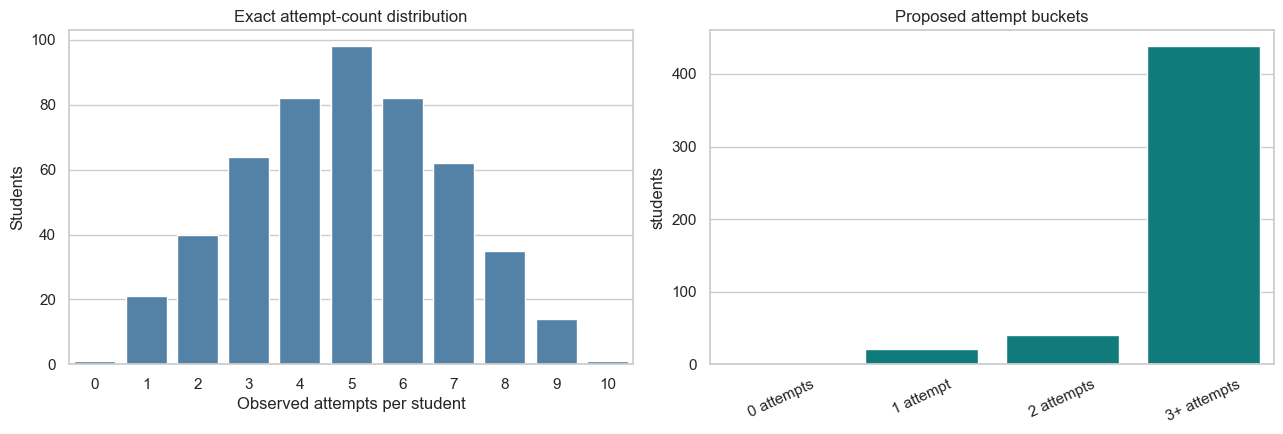

In [6]:
attempt_freq = (
    student_level["n_attempts"].value_counts().sort_index()
    .rename_axis("n_attempts").rename("students").reset_index()
)
attempt_freq["student_pct"] = 100 * attempt_freq["students"] / len(student_level)
display(attempt_freq)
bucket_order = ["0 attempts", "1 attempt", "2 attempts", "3+ attempts"]
bucket_summary = (student_level["attempt_bucket_3plus"].value_counts(sort=False)
                  .reindex(bucket_order, fill_value=0).rename("students").to_frame())
bucket_summary["student_pct"] = 100 * bucket_summary["students"] / len(student_level)
display(bucket_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=attempt_freq, x="n_attempts", y="students", color="steelblue", ax=axes[0])
axes[0].set_title("Exact attempt-count distribution")
axes[0].set_xlabel("Observed attempts per student")
axes[0].set_ylabel("Students")
sns.barplot(x=bucket_summary.index, y=bucket_summary["students"], color="darkcyan", ax=axes[1])
axes[1].set_title("Proposed attempt buckets")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


## 5. Last and penultimate attempt dates

Because there is no observed dropout timestamp, the last attempt date is only a proxy for dropout timing. The penultimate attempt date is the last point at which a prediction can be made if the last attempt is treated as the dropout event.

Students with fewer than two attempts have no penultimate attempt. The plots below show calendar-time patterns overall and by observed outcome label.


Students with a dated last attempt: 499
Students with a dated penultimate attempt: 478
Students without a penultimate attempt: 22


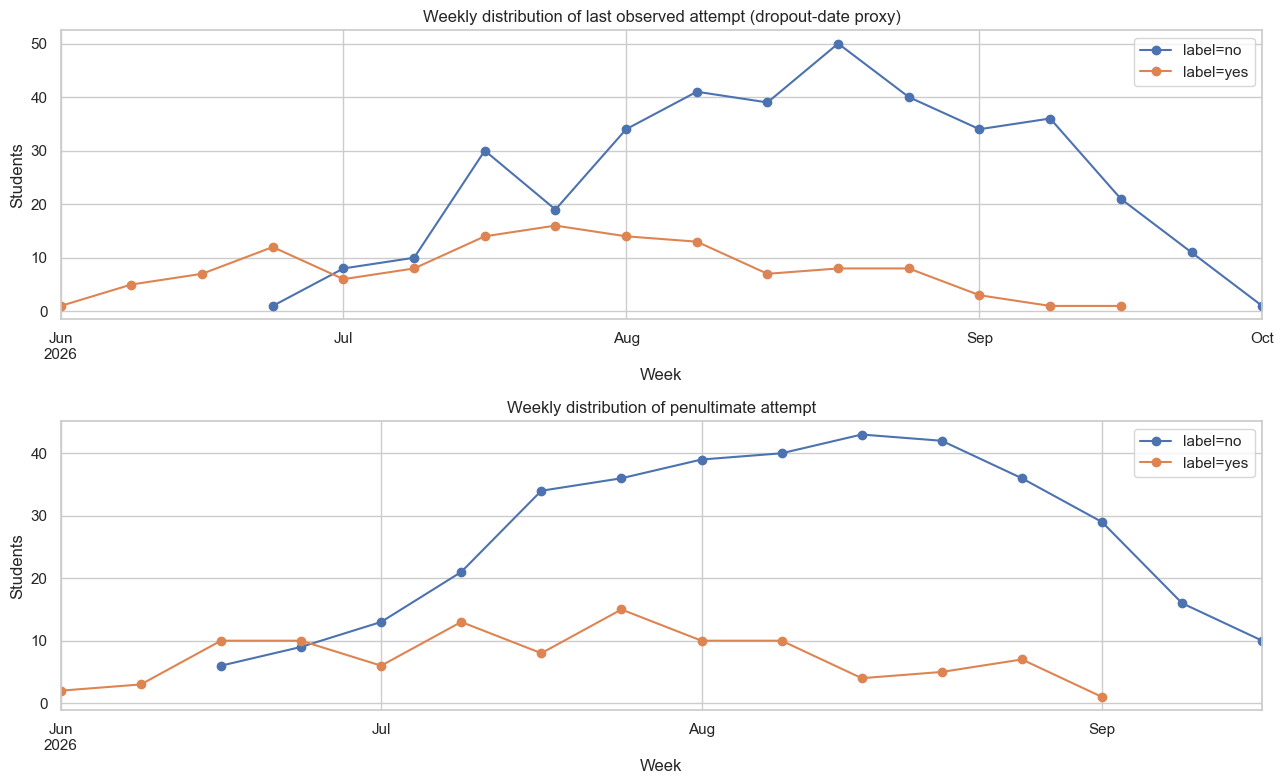

In [7]:
timeline = attempts[attempts["attempt_dt"].notna()].copy()
last_rows = timeline.groupby("student_id", as_index=False).tail(1).copy()
# Select exactly the second-to-last dated attempt for students with at least two dated attempts.
timeline["_dated_order"] = timeline.groupby("student_id").cumcount()
timeline["_dated_n"] = timeline.groupby("student_id")["attempt_id"].transform("size")
penultimate_rows = timeline.loc[timeline["_dated_order"] == timeline["_dated_n"] - 2].copy()

last_dates = last_rows[["student_id", "attempt_dt"]].rename(columns={"attempt_dt": "event_proxy_dt"}).merge(
    outcomes[["student_id", "dropped_out"]], on="student_id", how="left"
)
pen_dates = penultimate_rows[["student_id", "attempt_dt"]].rename(columns={"attempt_dt": "penultimate_dt"}).merge(
    outcomes[["student_id", "dropped_out"]], on="student_id", how="left"
)

print("Students with a dated last attempt:", last_dates["student_id"].nunique())
print("Students with a dated penultimate attempt:", pen_dates["student_id"].nunique())
print("Students without a penultimate attempt:", int((student_level["n_attempts"] < 2).sum()))

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for label, group in last_dates.groupby("dropped_out", dropna=False):
    group["event_proxy_dt"].dt.to_period("W").value_counts().sort_index().plot(
        ax=axes[0], label=f"label={label}", marker="o"
    )
axes[0].set_title("Weekly distribution of last observed attempt (dropout-date proxy)")
axes[0].set_xlabel("Week")
axes[0].set_ylabel("Students")
axes[0].legend()

for label, group in pen_dates.groupby("dropped_out", dropna=False):
    group["penultimate_dt"].dt.to_period("W").value_counts().sort_index().plot(
        ax=axes[1], label=f"label={label}", marker="o"
    )
axes[1].set_title("Weekly distribution of penultimate attempt")
axes[1].set_xlabel("Week")
axes[1].set_ylabel("Students")
axes[1].legend()
plt.tight_layout()
plt.show()


### Date distributions by calendar date

Weekly aggregation makes the overall shape readable; these histograms show the underlying date spread. Dates are not signup-relative here.


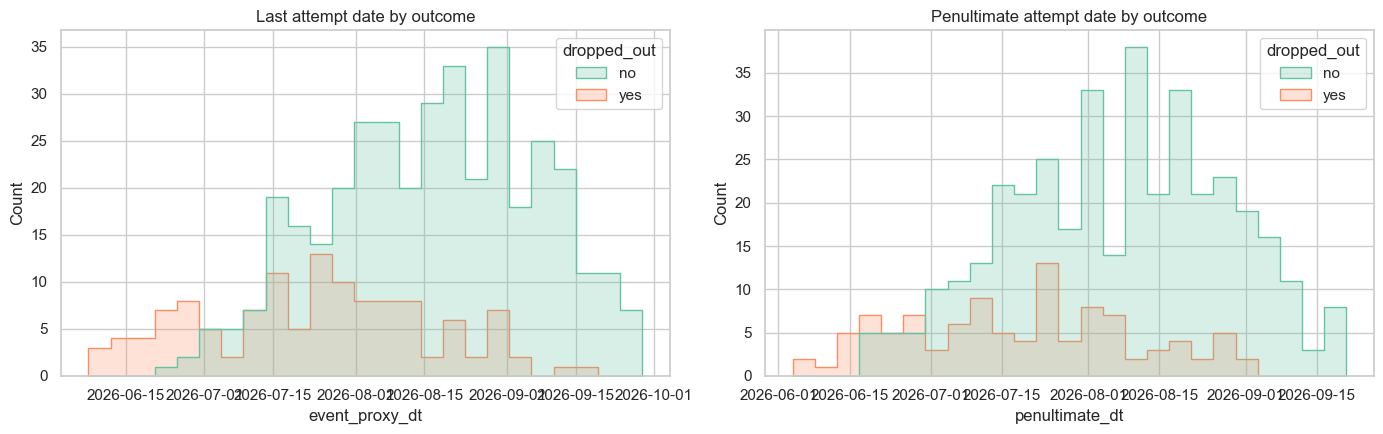

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(last_dates, x="event_proxy_dt", hue="dropped_out", bins=25, element="step", palette="Set2",
             stat="count", common_norm=False, ax=axes[0])
axes[0].set_title("Last attempt date by outcome")
sns.histplot(pen_dates, x="penultimate_dt", hue="dropped_out", bins=25, element="step", palette="Set2",
             stat="count", common_norm=False, ax=axes[1])
axes[1].set_title("Penultimate attempt date by outcome")
plt.tight_layout()
plt.show()


## 6. Attempts relative to signup and time between attempts

Calendar dates can be confounded by when students joined. This section compares days from signup to first/last/penultimate attempt and the gaps between consecutive attempts. Negative days from signup are flagged rather than silently discarded.


Attempts before signup: 0


,days_from_signup
count,2453.000000
mean,25.432532
std,19.839569
min,0.000000
25%,9.000000
50%,21.000000
75%,38.000000
max,104.000000


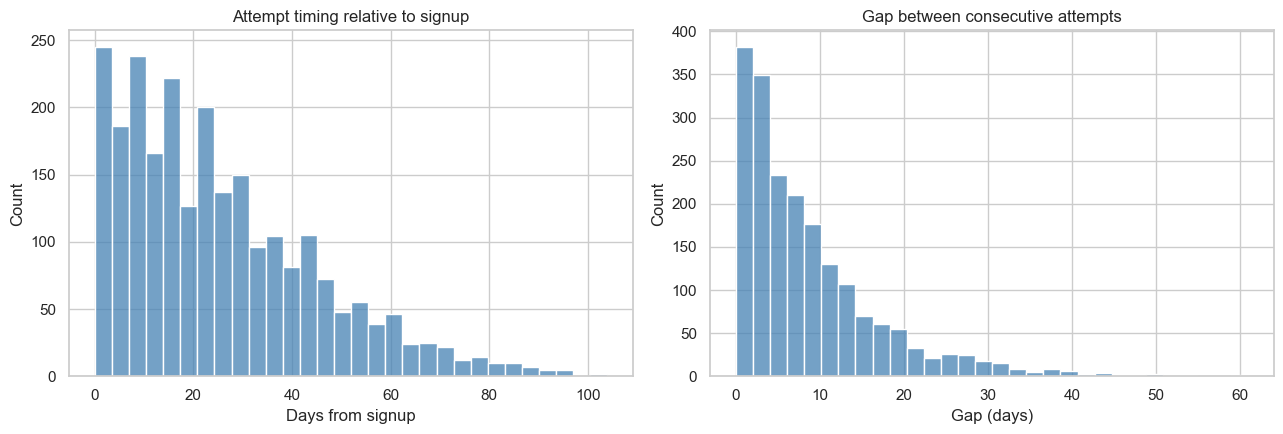

,count,mean,std,min,25%,50%,75%,max
first_days_from_signup,499.0,6.25,5.34,0.00,2.00,5.00,9.00,25.00
last_days_from_signup,499.0,40.11,21.99,0.00,24.00,39.00,55.00,104.00
median_gap_days,478.0,8.63,6.75,0.12,4.23,6.98,10.80,47.33
max_gap_days,478.0,17.59,10.18,0.43,10.02,15.34,23.18,61.02


In [9]:
student_dates = student_level[["student_id", "signup_dt", "n_attempts"]].copy()
attempt_dates = timeline.merge(students[["student_id", "signup_dt"]], on="student_id", how="left")
attempt_dates["days_from_signup"] = (
    attempt_dates["attempt_dt"].dt.normalize() - attempt_dates["signup_dt"].dt.normalize()
).dt.days
print("Attempts before signup:", int((attempt_dates["days_from_signup"] < 0).sum()))
display(attempt_dates["days_from_signup"].describe().to_frame("days_from_signup"))

attempt_dates["gap_days"] = attempt_dates.groupby("student_id")["attempt_dt"].diff().dt.total_seconds() / 86400
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(attempt_dates["days_from_signup"].dropna(), bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Attempt timing relative to signup")
axes[0].set_xlabel("Days from signup")
sns.histplot(attempt_dates.loc[attempt_dates["gap_days"].notna(), "gap_days"], bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Gap between consecutive attempts")
axes[1].set_xlabel("Gap (days)")
plt.tight_layout()
plt.show()

first_last = attempt_dates.groupby("student_id").agg(
    first_days_from_signup=("days_from_signup", "min"),
    last_days_from_signup=("days_from_signup", "max"),
    median_gap_days=("gap_days", "median"),
    max_gap_days=("gap_days", "max"),
).reset_index()
display(first_last.describe().T.round(2))


## 7. Attempts by lesson/module

The dataset calls this field `lesson_id`; below, “lesson/module” means the same field. We inspect overall attempt volume, student coverage, and the relationship between each student's total attempt count and lessons attempted.

The cross-tab uses **students** (whether they ever attempted a lesson), not raw attempt rows, so students who retry the same lesson do not inflate lesson coverage.


,attempt_rows,unique_students,mean_score,median_score,mean_time_min,median_time_min
lesson_id,,,,,,
L1,928,498,69.54,69.0,24.05,23.7
L2,852,427,71.32,72.0,24.86,24.9
L3,673,338,70.75,71.0,24.72,24.3


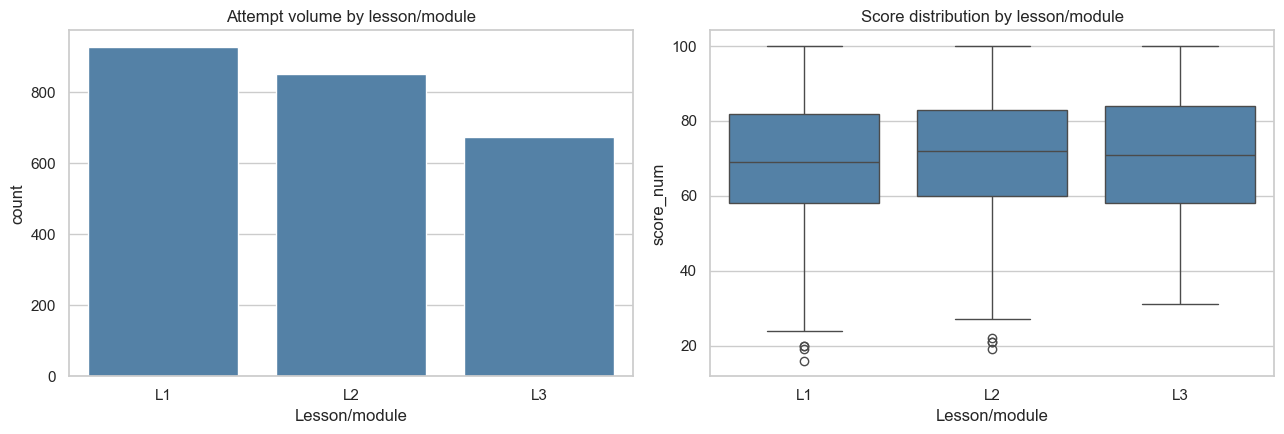

/var/folders/yn/44lxv0l14pv2b3g2vnm1bjsr0000gn/T/ipykernel_6280/1122168636.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  student_lesson_counts = student_lesson.groupby("attempt_bucket_3plus").sum(numeric_only=True).reindex(


,L1,L2,L3
attempt_bucket_3plus,,,
0 attempts,0,0,0
1 attempt,20,1,0
2 attempts,40,20,6
3+ attempts,438,406,332


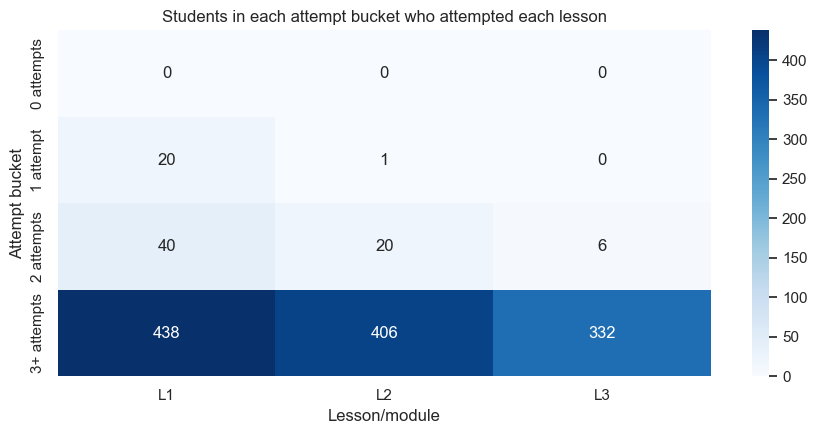

In [10]:
lesson_attempts = attempts.groupby("lesson_id", dropna=False).agg(
    attempt_rows=("attempt_id", "count"),
    unique_students=("student_id", "nunique"),
    mean_score=("score_num", "mean"),
    median_score=("score_num", "median"),
    mean_time_min=("time_spent_num", "mean"),
    median_time_min=("time_spent_num", "median"),
).sort_values("attempt_rows", ascending=False)
display(lesson_attempts.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=attempts, x="lesson_id", order=sorted(attempts["lesson_id"].dropna().unique()), color="steelblue", ax=axes[0])
axes[0].set_title("Attempt volume by lesson/module")
axes[0].set_xlabel("Lesson/module")
sns.boxplot(data=attempts, x="lesson_id", y="score_num", color="steelblue", ax=axes[1])
axes[1].set_title("Score distribution by lesson/module")
axes[1].set_xlabel("Lesson/module")
plt.tight_layout()
plt.show()

student_lesson = pd.crosstab(attempts["student_id"], attempts["lesson_id"]).gt(0)
student_lesson = student_lesson.join(student_level.set_index("student_id")["attempt_bucket_3plus"])
student_lesson_counts = student_lesson.groupby("attempt_bucket_3plus").sum(numeric_only=True).reindex(
    ["0 attempts", "1 attempt", "2 attempts", "3+ attempts"]
)
display(student_lesson_counts.astype(int))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(student_lesson_counts, annot=True, fmt=".0f", cmap="Blues", ax=ax)
ax.set_title("Students in each attempt bucket who attempted each lesson")
ax.set_xlabel("Lesson/module")
ax.set_ylabel("Attempt bucket")
plt.tight_layout()
plt.show()


## 8. Time spent: total, per attempt, and by lesson/module

Time spent is examined at both event level and student level. Total time naturally increases with the number of attempts, so compare **per-attempt averages/medians** as well as total time. Missing and non-positive durations are surfaced explicitly.


Missing time_spent_min: 95
Negative durations: 0
Zero durations: 0


,time_spent_min
count,2358.000000
mean,24.513825
std,9.081232
min,2.000000
10%,12.700000
25%,18.400000
50%,24.200000
75%,30.675000
90%,36.300000
max,53.000000


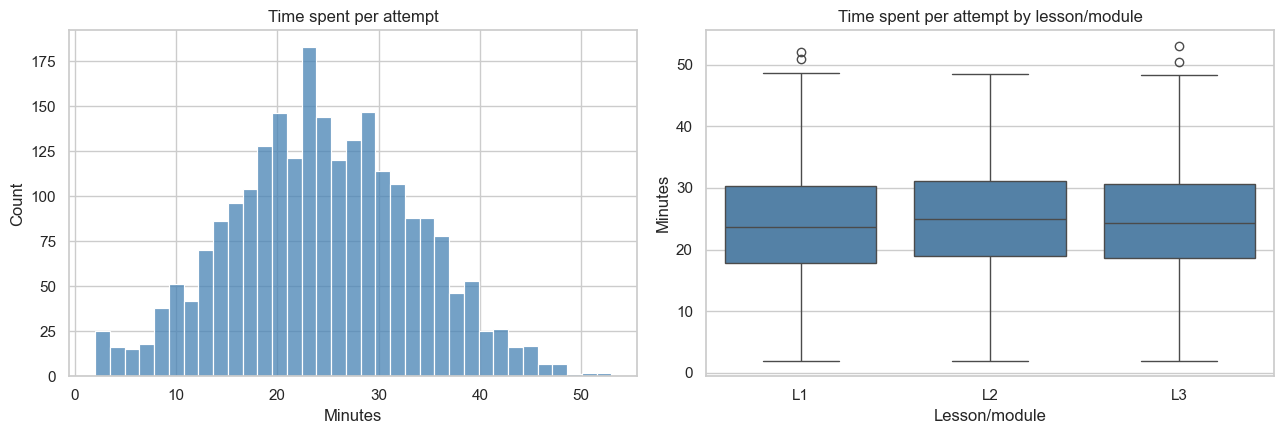

,students,median_total_time_min,mean_total_time_min,median_mean_time_min,mean_mean_time_min,median_attempts
attempt_bucket_3plus,,,,,,
0 attempts,1,NaN,NaN,NaN,NaN,0.0
1 attempt,21,21.00,18.24,21.35,19.16,1.0
2 attempts,40,39.05,42.61,20.20,21.63,2.0
3+ attempts,438,126.20,127.21,24.76,24.60,5.0


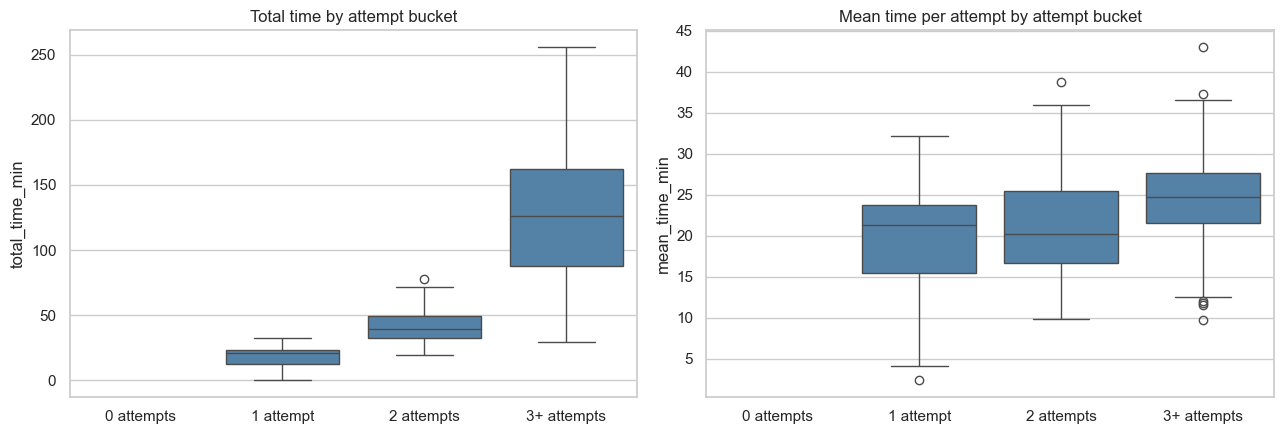

In [11]:
print("Missing time_spent_min:", int(attempts["time_spent_num"].isna().sum()))
print("Negative durations:", int((attempts["time_spent_num"] < 0).sum()))
print("Zero durations:", int((attempts["time_spent_num"] == 0).sum()))
display(attempts["time_spent_num"].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame("time_spent_min"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(attempts["time_spent_num"].dropna(), bins=35, ax=axes[0], color="steelblue")
axes[0].set_title("Time spent per attempt")
axes[0].set_xlabel("Minutes")
sns.boxplot(data=attempts, x="lesson_id", y="time_spent_num", color="steelblue", ax=axes[1])
axes[1].set_title("Time spent per attempt by lesson/module")
axes[1].set_xlabel("Lesson/module")
axes[1].set_ylabel("Minutes")
plt.tight_layout()
plt.show()

time_by_bucket = student_level.groupby("attempt_bucket_3plus", observed=False).agg(
    students=("student_id", "nunique"),
    median_total_time_min=("total_time_min", "median"),
    mean_total_time_min=("total_time_min", "mean"),
    median_mean_time_min=("mean_time_min", "median"),
    mean_mean_time_min=("mean_time_min", "mean"),
    median_attempts=("n_attempts", "median"),
)
display(time_by_bucket.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=student_level, x="attempt_bucket_3plus", y="total_time_min", order=bucket_order, color="steelblue", ax=axes[0])
axes[0].set_title("Total time by attempt bucket")
axes[0].set_xlabel("")
sns.boxplot(data=student_level, x="attempt_bucket_3plus", y="mean_time_min", order=bucket_order, color="steelblue", ax=axes[1])
axes[1].set_title("Mean time per attempt by attempt bucket")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()


## 9. Scores and learning activity across attempts


,attempts,valid_scores,mean_score,median_score,score_std
lesson_id,,,,,
L1,928,928,69.54,69.0,16.84
L2,852,850,71.32,72.0,16.11
L3,673,672,70.75,71.0,16.71


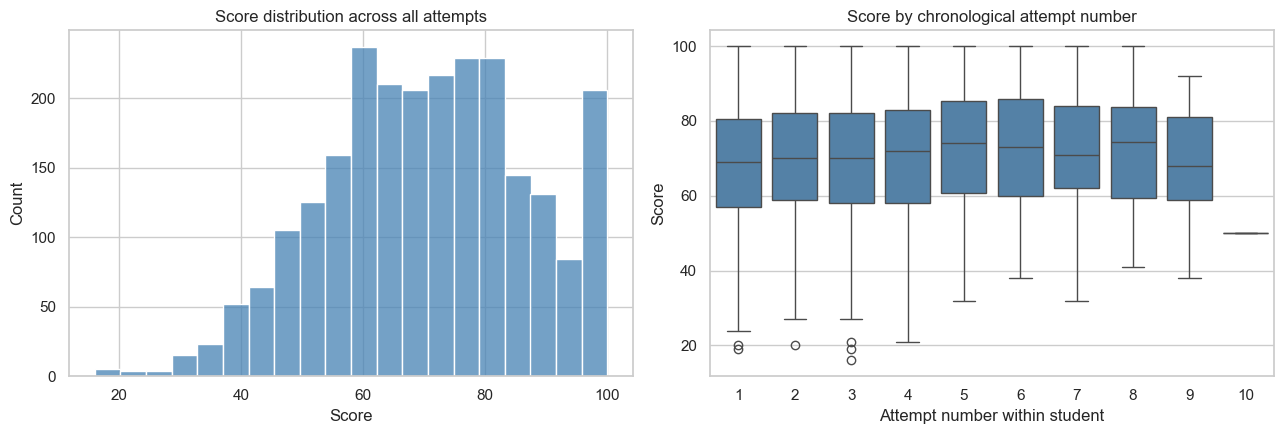

,attempt_number,count,mean,median,std
0,1,499,68.56,69.0,17.09
1,2,478,70.08,70.0,16.13
2,3,438,69.97,70.0,16.79
3,4,372,70.73,72.0,16.39
4,5,292,72.80,74.0,16.41
5,6,194,72.56,73.0,16.21
6,7,111,71.76,71.0,15.75
7,8,50,73.08,74.5,16.67
8,9,15,68.20,68.0,17.47
9,10,1,50.00,50.0,NaN


In [12]:
display(attempts.groupby("lesson_id").agg(
    attempts=("attempt_id", "size"),
    valid_scores=("score_num", "count"),
    mean_score=("score_num", "mean"),
    median_score=("score_num", "median"),
    score_std=("score_num", "std"),
).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(attempts["score_num"].dropna(), bins=20, ax=axes[0], color="steelblue")
axes[0].set_title("Score distribution across all attempts")
axes[0].set_xlabel("Score")
sns.boxplot(data=attempts, x="attempt_number", y="score_num", color="steelblue", ax=axes[1])
axes[1].set_title("Score by chronological attempt number")
axes[1].set_xlabel("Attempt number within student")
axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

# Student-level progression: average score at each attempt ordinal
score_progression = attempts.groupby("attempt_number")["score_num"].agg(["count", "mean", "median", "std"]).reset_index()
display(score_progression.round(2))


## 10. Attempt count × lesson/module × outcome cross-tabs

These tables separate raw attempt volume from student coverage and allow inspection of whether lesson exposure and attempt depth differ across observed outcomes. These are descriptive associations, not causal effects.

`refund_requested` is included only as a descriptive cohort field here. Its availability time is unknown, so it should not automatically be used as a model feature.


In [13]:
# Outcome distribution across attempt buckets
outcome_by_bucket = pd.crosstab(
    student_level["attempt_bucket_3plus"], student_level["dropped_out"], margins=True
)
display(outcome_by_bucket)
display(pd.crosstab(
    student_level["attempt_bucket_3plus"], student_level["dropout_label"], normalize="index"
).round(3).rename(columns={0: "not_dropped_out_share", 1: "dropped_out_share"}))

# Lesson exposure by attempt bucket and outcome
student_lesson_flags = pd.crosstab(attempts["student_id"], attempts["lesson_id"]).gt(0)
student_lesson_flags = student_lesson_flags.join(
    student_level.set_index("student_id")[["attempt_bucket_3plus", "dropped_out"]]
)
for lesson in [c for c in student_lesson_flags.columns if c not in ["attempt_bucket_3plus", "dropped_out"]]:
    print(f"Student exposure to {lesson} by attempt bucket and outcome")
    display(pd.crosstab(
        [student_lesson_flags["attempt_bucket_3plus"], student_lesson_flags["dropped_out"]],
        student_lesson_flags[lesson], normalize="index"
    ).round(3))


dropped_out,no,yes,All
attempt_bucket_3plus,,,
0 attempts,0,1,1
1 attempt,1,20,21
2 attempts,16,24,40
3+ attempts,358,80,438
All,375,125,500


dropout_label,not_dropped_out_share,dropped_out_share
attempt_bucket_3plus,,
0 attempts,0.000,1.000
1 attempt,0.048,0.952
2 attempts,0.400,0.600
3+ attempts,0.817,0.183


Student exposure to L1 by attempt bucket and outcome


L1                                False  True 
attempt_bucket_3plus dropped_out              
1 attempt            no            0.00   1.00
                     yes           0.05   0.95
2 attempts           no            0.00   1.00
                     yes           0.00   1.00
3+ attempts          no            0.00   1.00
                     yes           0.00   1.00

Student exposure to L2 by attempt bucket and outcome


L2                                False  True 
attempt_bucket_3plus dropped_out              
1 attempt            no           1.000  0.000
                     yes          0.950  0.050
2 attempts           no           0.375  0.625
                     yes          0.583  0.417
3+ attempts          no           0.056  0.944
                     yes          0.150  0.850

Student exposure to L3 by attempt bucket and outcome


L3                                False  True 
attempt_bucket_3plus dropped_out              
1 attempt            no           1.000  0.000
                     yes          1.000  0.000
2 attempts           no           0.875  0.125
                     yes          0.833  0.167
3+ attempts          no           0.215  0.785
                     yes          0.362  0.638

## 11. First, penultimate, and last attempt characteristics

This comparison can reveal whether the final observed event looks different from the event before it. It is still descriptive: if the target label says “not dropped out,” the final attempt date is not necessarily a dropout event. Treat the proxy as an explicit working assumption, not a verified fact.


,students,mean_score,median_score,mean_time_min,median_time_min
event_position,,,,,
first,499,68.56,69.0,24.00,23.4
last,499,69.06,69.5,24.44,24.4
penultimate,478,70.22,70.0,24.49,24.0


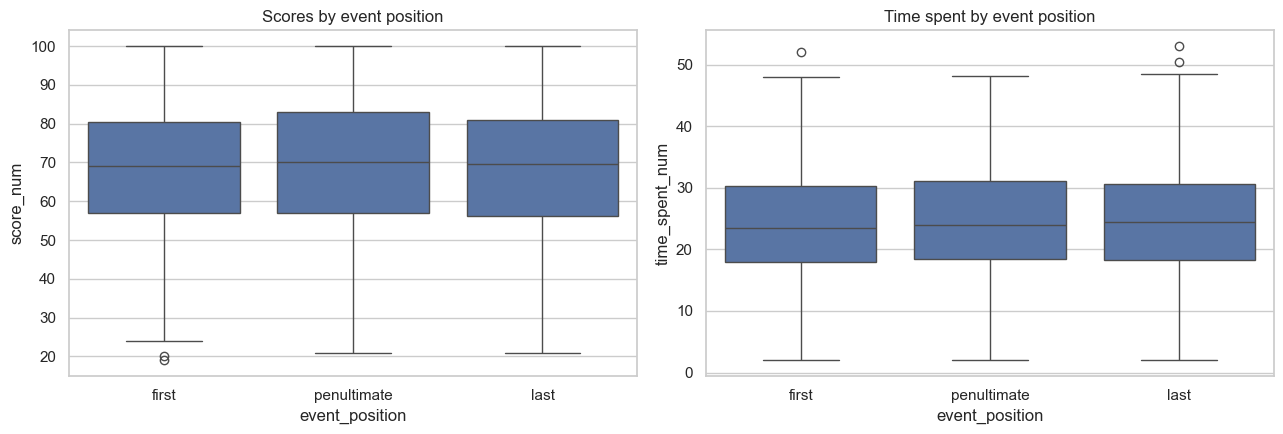

In [14]:
# Use chronologically sorted attempts. Students with one dated attempt have no penultimate event.
last_event = timeline.groupby("student_id", as_index=False).tail(1).copy()
timeline["_dated_order"] = timeline.groupby("student_id").cumcount()
timeline["_dated_n"] = timeline.groupby("student_id")["attempt_id"].transform("size")
penultimate_event = timeline.loc[timeline["_dated_order"] == timeline["_dated_n"] - 2].copy()
first_event = timeline.groupby("student_id", as_index=False).head(1).copy()

def event_summary(df, label):
    out = df[["student_id", "score_num", "time_spent_num", "lesson_id"]].copy()
    out["event_position"] = label
    return out

event_compare = pd.concat([
    event_summary(first_event, "first"),
    event_summary(penultimate_event, "penultimate"),
    event_summary(last_event, "last"),
], ignore_index=True)
display(event_compare.groupby("event_position").agg(
    students=("student_id", "nunique"),
    mean_score=("score_num", "mean"),
    median_score=("score_num", "median"),
    mean_time_min=("time_spent_num", "mean"),
    median_time_min=("time_spent_num", "median"),
).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=event_compare, x="event_position", y="score_num",
            order=["first", "penultimate", "last"], ax=axes[0])
axes[0].set_title("Scores by event position")
sns.boxplot(data=event_compare, x="event_position", y="time_spent_num",
            order=["first", "penultimate", "last"], ax=axes[1])
axes[1].set_title("Time spent by event position")
plt.tight_layout()
plt.show()


## 12. Module-specific student profiles and potential feature families

A student can be strong in one lesson/module and struggle in another. The next cells construct **EDA-only** student-by-module summaries: valid-score mean/median/minimum, score variability, attempt count, time mean/median/total, and missingness/coverage. They are not yet a modeling dataset. Wide features are useful for later classification, but only module information available by the prediction point may be used. A module never attempted should remain distinguishable from an attempted module whose score/time is missing.

,metric,count
0,raw score rows,2453
1,raw 999 sentinel rows,3
2,missing raw scores,0
3,valid analytical scores,2450


Raw score values (including sentinels): [np.int64(16), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(24), np.int64(27), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61)]


,student_id,lesson_id,module_attempts,module_valid_score_n,module_score_mean,module_score_median,module_score_min,module_score_std,module_time_observed_n,module_time_mean_min,module_time_median_min,module_time_total_min,dropped_out,dropout_label,attempt_bucket_3plus,module_score_missing_all,module_time_missing_all
0,S001,L1,3,3,86.666667,86.0,82.0,5.033223,2,17.000000,17.00,34.0,no,0,3+ attempts,False,False
1,S002,L1,2,2,68.000000,68.0,59.0,12.727922,2,44.700000,44.70,89.4,no,0,3+ attempts,False,False
2,S002,L2,3,3,65.333333,64.0,63.0,3.214550,2,17.250000,17.25,34.5,no,0,3+ attempts,False,False
3,S002,L3,2,2,46.000000,46.0,43.0,4.242641,2,31.600000,31.60,63.2,no,0,3+ attempts,False,False
4,S003,L1,1,1,66.000000,66.0,66.0,NaN,1,8.700000,8.70,8.7,no,0,3+ attempts,False,False
5,S003,L2,2,2,74.000000,74.0,70.0,5.656854,2,24.850000,24.85,49.7,no,0,3+ attempts,False,False
6,S003,L3,3,3,73.000000,79.0,57.0,14.000000,3,25.200000,23.60,75.6,no,0,3+ attempts,False,False
7,S004,L1,1,1,58.000000,58.0,58.0,NaN,1,33.100000,33.10,33.1,no,0,3+ attempts,False,False
8,S004,L3,2,2,62.500000,62.5,59.0,4.949747,2,30.050000,30.05,60.1,no,0,3+ attempts,False,False
9,S005,L1,2,2,98.500000,98.5,97.0,2.121320,2,30.200000,30.20,60.4,no,0,3+ attempts,False,False


,lesson_id,dropped_out,students_exposed,module_attempts,mean_score,median_student_module_score,mean_time_per_attempt_min,median_time_per_attempt_min,mean_module_total_time_min,score_missing_all_students,time_missing_all_students
0,L1,no,375,745,70.584,70.0,24.753,25.200,47.282,0,5
1,L1,yes,123,183,60.504,60.5,20.905,21.225,30.623,0,1
2,L2,no,348,728,71.592,72.0,25.557,25.200,51.259,0,7
3,L2,yes,79,124,63.789,63.0,20.402,20.600,30.690,0,2
4,L3,no,283,586,70.811,71.0,25.531,25.300,50.287,0,2
5,L3,yes,55,87,62.518,59.0,22.251,21.600,32.953,0,0


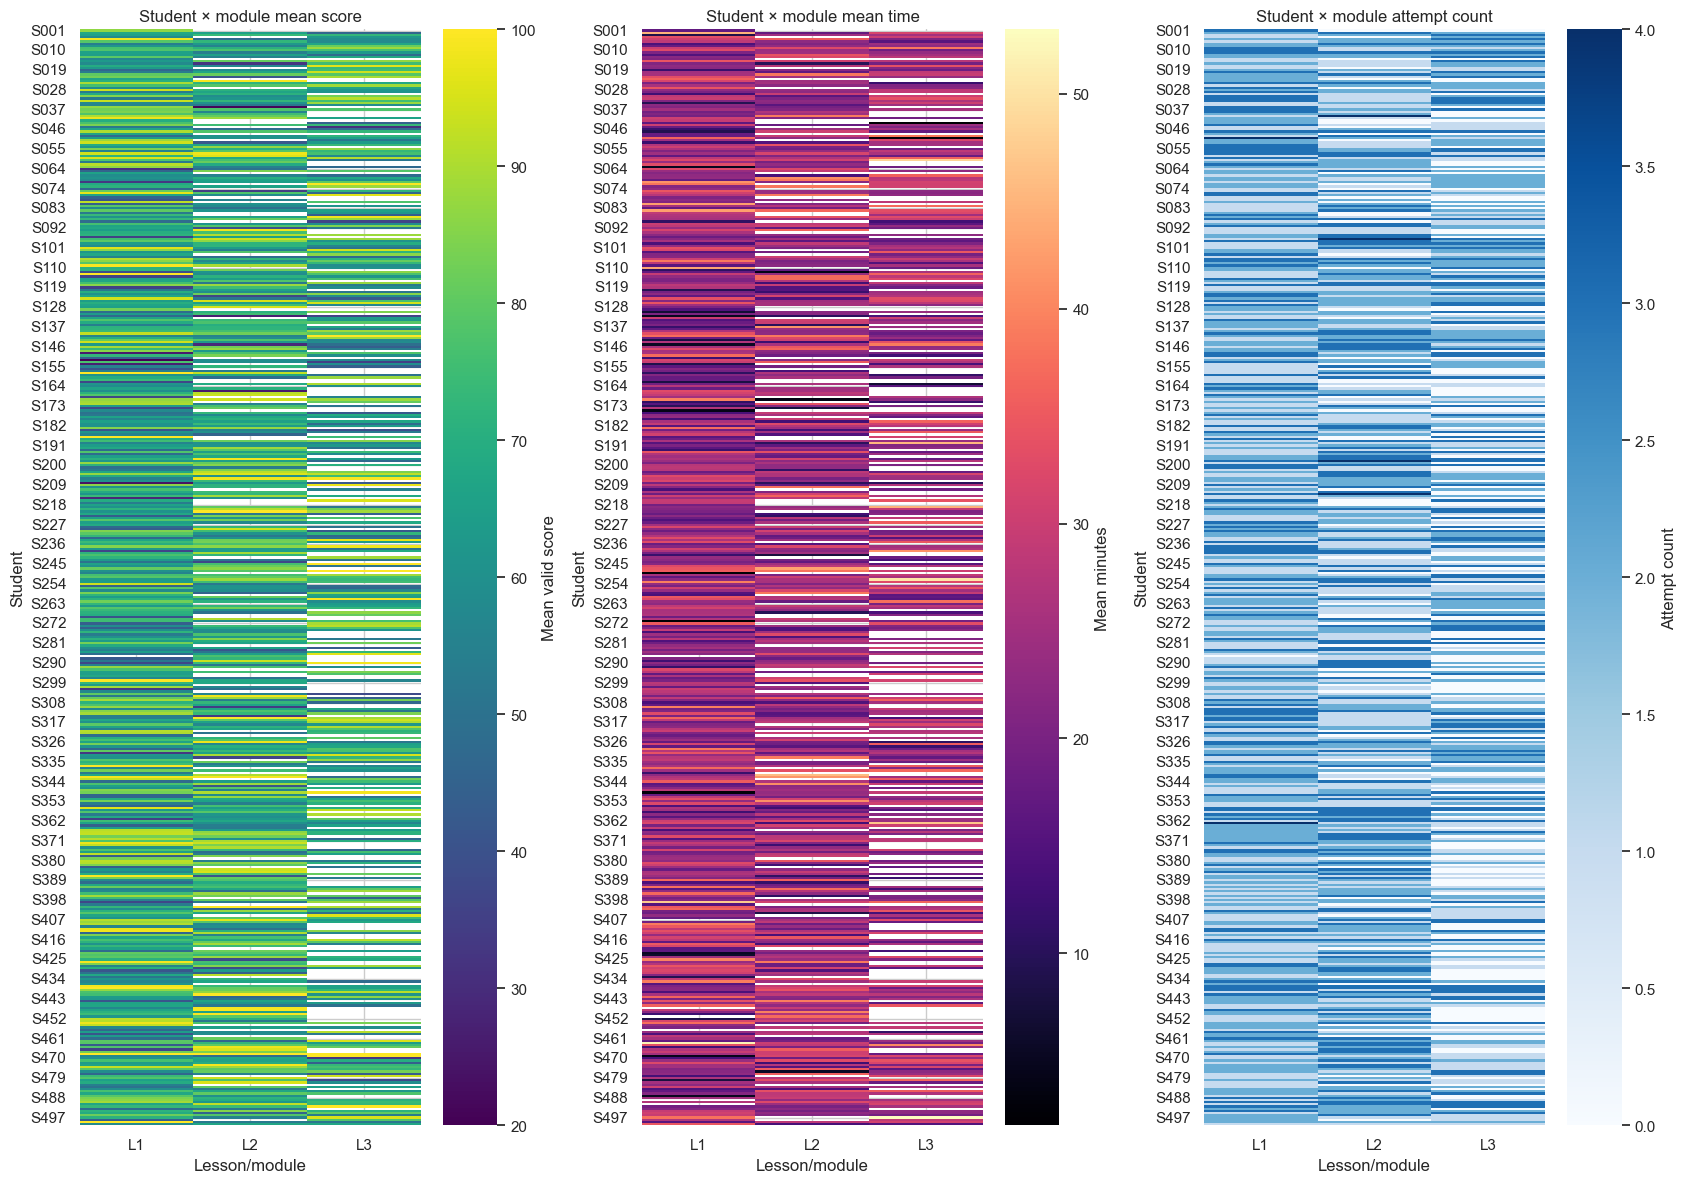

,student_id,dropped_out,dropout_label,n_attempts,module_mean_score__L1,module_mean_score__L2,module_mean_score__L3,module_mean_time_min__L1,module_mean_time_min__L2,module_mean_time_min__L3,module_attempt_count__L1,module_attempt_count__L2,module_attempt_count__L3,module_seen__L1,module_seen__L2,module_seen__L3
0,S001,no,0,3,86.666667,NaN,NaN,17.0,NaN,NaN,3.0,0.0,0.0,1.0,0.0,0.0
1,S002,no,0,7,68.000000,65.333333,46.0,44.7,17.25,31.600000,2.0,3.0,2.0,1.0,1.0,1.0
2,S003,no,0,6,66.000000,74.000000,73.0,8.7,24.85,25.200000,1.0,2.0,3.0,1.0,1.0,1.0
3,S004,no,0,3,58.000000,NaN,62.5,33.1,NaN,30.050000,1.0,0.0,2.0,1.0,0.0,1.0
4,S005,no,0,7,98.500000,47.000000,59.0,30.2,35.15,21.033333,2.0,2.0,3.0,1.0,1.0,1.0


Candidate wide feature shape (EDA only): (500, 16)


,students,median_modules_scored,median_best_module_score,median_worst_module_score,median_score_range,median_score_std_across_modules
dropped_out,,,,,,
no,375,3.0,84.0,60.00,22.00,12.366
yes,124,2.0,70.0,52.75,11.75,11.137


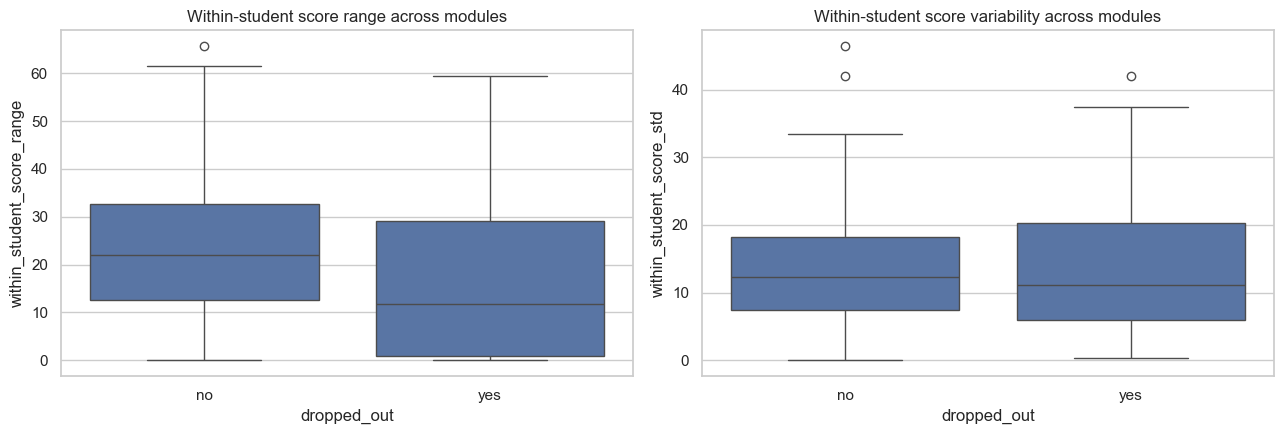

In [15]:
# Audit the sentinel before looking at cleaned score summaries.
score_sentinel_audit = pd.DataFrame({
    "metric": ["raw score rows", "raw 999 sentinel rows", "missing raw scores", "valid analytical scores"],
    "count": [len(attempts), int(attempts["score_raw_num"].eq(999).sum()),
              int(attempts["score_raw_num"].isna().sum()), int(attempts["score_num"].notna().sum())],
})
display(score_sentinel_audit)
print("Raw score values (including sentinels):", sorted(attempts["score_raw_num"].dropna().unique())[:40])

# Per-student, per-module metrics. Missing scores/times are ignored by numeric aggregations,
# while counts and missingness flags make coverage explicit.
module_student = attempts.groupby(["student_id", "lesson_id"], dropna=False).agg(
    module_attempts=("attempt_id", "count"),
    module_valid_score_n=("score_num", "count"),
    module_score_mean=("score_num", "mean"),
    module_score_median=("score_num", "median"),
    module_score_min=("score_num", "min"),
    module_score_std=("score_num", "std"),
    module_time_observed_n=("time_spent_num", "count"),
    module_time_mean_min=("time_spent_num", "mean"),
    module_time_median_min=("time_spent_num", "median"),
    module_time_total_min=("time_spent_num", "sum"),
).reset_index()
module_student = module_student.merge(
    student_level[["student_id", "dropped_out", "dropout_label", "attempt_bucket_3plus"]],
    on="student_id", how="left", validate="many_to_one"
)
module_student["module_score_missing_all"] = module_student["module_valid_score_n"].eq(0)
module_student["module_time_missing_all"] = module_student["module_time_observed_n"].eq(0)
display(module_student.sort_values(["student_id", "lesson_id"]).head(15))

# Module-level outcomes: descriptive, unadjusted comparisons only. Include denominators.
module_outcome = module_student.groupby(["lesson_id", "dropped_out"], dropna=False).agg(
    students_exposed=("student_id", "nunique"),
    module_attempts=("module_attempts", "sum"),
    mean_score=("module_score_mean", "mean"),
    median_student_module_score=("module_score_median", "median"),
    mean_time_per_attempt_min=("module_time_mean_min", "mean"),
    median_time_per_attempt_min=("module_time_median_min", "median"),
    mean_module_total_time_min=("module_time_total_min", "mean"),
    score_missing_all_students=("module_score_missing_all", "sum"),
    time_missing_all_students=("module_time_missing_all", "sum"),
).reset_index()
display(module_outcome.round(3))

# Heatmaps: students x modules, one value per student/module. NaN means no observed valid score.
score_wide = module_student.pivot(index="student_id", columns="lesson_id", values="module_score_mean")
time_wide = module_student.pivot(index="student_id", columns="lesson_id", values="module_time_mean_min")
coverage_wide = module_student.pivot(index="student_id", columns="lesson_id", values="module_attempts").fillna(0)
fig, axes = plt.subplots(1, 3, figsize=(17, max(5, min(12, len(score_wide) * 0.025))))
sns.heatmap(score_wide, cmap="viridis", ax=axes[0], cbar_kws={"label": "Mean valid score"})
axes[0].set_title("Student × module mean score")
sns.heatmap(time_wide, cmap="magma", ax=axes[1], cbar_kws={"label": "Mean minutes"})
axes[1].set_title("Student × module mean time")
sns.heatmap(coverage_wide, cmap="Blues", ax=axes[2], cbar_kws={"label": "Attempt count"})
axes[2].set_title("Student × module attempt count")
for ax in axes: ax.set_xlabel("Lesson/module"); ax.set_ylabel("Student")
plt.tight_layout(); plt.show()

# Student-level wide feature *candidates* for later feature engineering, not training yet.
# Keep absent-module NaNs and create explicit exposure indicators rather than silently filling all with zero.
module_score_features = score_wide.add_prefix("module_mean_score__")
module_time_features = time_wide.add_prefix("module_mean_time_min__")
module_attempt_features = coverage_wide.add_prefix("module_attempt_count__")
module_exposure_features = coverage_wide.gt(0).astype(int).add_prefix("module_seen__")
module_feature_candidates = (student_level[["student_id", "dropped_out", "dropout_label", "n_attempts"]]
    .merge(module_score_features, on="student_id", how="left")
    .merge(module_time_features, on="student_id", how="left")
    .merge(module_attempt_features, on="student_id", how="left")
    .merge(module_exposure_features, on="student_id", how="left"))
display(module_feature_candidates.head())
print("Candidate wide feature shape (EDA only):", module_feature_candidates.shape)

# Within-student contrasts can reveal specialization / mismatch between modules.
# Calculate only across modules with observed valid scores; record how many modules contribute.
module_score_profile = score_wide.copy()
student_module_contrasts = pd.DataFrame({
    "student_id": module_score_profile.index,
    "modules_with_valid_score": module_score_profile.notna().sum(axis=1).values,
    "best_module_mean_score": module_score_profile.max(axis=1).values,
    "worst_module_mean_score": module_score_profile.min(axis=1).values,
    "within_student_score_range": (module_score_profile.max(axis=1) - module_score_profile.min(axis=1)).values,
    "within_student_score_std": module_score_profile.std(axis=1).values,
}).merge(student_level[["student_id", "dropped_out", "dropout_label", "n_attempts"]], on="student_id", how="left")
display(student_module_contrasts.groupby("dropped_out").agg(
    students=("student_id", "nunique"),
    median_modules_scored=("modules_with_valid_score", "median"),
    median_best_module_score=("best_module_mean_score", "median"),
    median_worst_module_score=("worst_module_mean_score", "median"),
    median_score_range=("within_student_score_range", "median"),
    median_score_std_across_modules=("within_student_score_std", "median"),
).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=student_module_contrasts, x="dropped_out", y="within_student_score_range", ax=axes[0])
axes[0].set_title("Within-student score range across modules")
sns.boxplot(data=student_module_contrasts, x="dropped_out", y="within_student_score_std", ax=axes[1])
axes[1].set_title("Within-student score variability across modules")
plt.tight_layout(); plt.show()


## 13. Caveats and feature-engineering checklist

Treat this as a working data contract. Revisit each item before building training tables.

- **Score sentinel:** raw score `999` is excluded from analytical score statistics; preserve a raw audit field and verify the sentinel meaning with the source owner.
- **Missing score/time:** do not blindly impute. Create observation counts / missingness indicators where meaningful; calculate means only over valid observations.
- **Unattempted module vs missing measurement:** no row for a module means no observed exposure; an existing module row with missing score/time means exposure exists but measurement is absent. Encode these separately.
- **No dropout timestamp:** last attempt is only a proxy. It may be the last recorded activity, not the true dropout date. Penultimate attempt is a proposed prediction point, not proof that dropout occurs immediately after it.
- **Target semantics:** eventual `dropped_out` label is not the same as “dropped out by attempt k.” For the attempt-k datasets, define the estimand explicitly and do not label future dropouts as currently dropped out at earlier attempts without a defensible target definition.
- **Prediction-time leakage:** features for a k-attempt model must use only attempts 1..k. Last/penultimate dates, total lifetime attempts, final lesson, eventual refund, or any aggregate computed using later events can leak future information unless genuinely known at prediction time.
- **Unequal observation opportunity:** students who signed up earlier have had more time to attempt lessons. Include signup-relative time / observation window in analysis, and use time-based validation if deployment is future-facing.
- **Module confounding:** students may self-select modules and attempt counts differ. Compare module outcomes with denominators and avoid causal claims; module means based on one attempt are noisier than means based on many.
- **Small groups / sparse modules:** report denominators and valid score counts. Avoid interpreting tiny cells or high variance as robust student traits.
- **Time-spent quality:** missing, zero, negative, and extreme durations may reflect instrumentation or abandoned sessions. Inspect raw values before clipping/winsorizing; don't infer engagement from time alone.
- **Repeated attempts:** rows are not independent. Split train/test by student, not attempt row, to prevent the same student appearing in both sets.
- **Date quality:** invalid timestamps, ties, attempts before signup, and timezone conventions affect chronological ordering and elapsed-time features. Define deterministic tie handling.
- **Small dataset:** only 500 students and 2,453 attempts are present in the supplied files. Wide module features can be sparse and overfit; use regularization, grouped validation, and missingness-aware baselines.
- **Outcome and join integrity:** verify one outcome per student and unmatched IDs; avoid assuming missing labels mean “not dropped out.”

Suggested module feature families for the next stage: (1) per-module score mean/median/minimum/std and valid-score count; (2) per-module mean/median/total time and observed-time count; (3) module exposure and attempt counts; (4) first-to-last score change within module; (5) best-vs-worst module score gap; (6) module-specific missingness; (7) score/time trends by attempt ordinal within module. All must be truncated at the chosen prediction point.

## 14. Data-quality summary and conclusions to carry into feature engineering

This final section prints compact checks and a table of cohort sizes. Use the findings from the executed notebook to choose features; do not use this EDA to make claims about causal dropout behavior.

### Modeling guardrails
- Do not use the final observed attempt's score, duration, lesson, or timestamp as features for a prediction made at the penultimate attempt.
- Do not use `dropped_out` itself as a feature.
- Treat `refund_requested` cautiously because its timestamp/availability is unknown.
- Keep no-attempt and one-attempt students visible in cohort accounting; their eligibility differs for a penultimate-attempt prediction.
- Resolve the exact attempt-bucket target definition before training. With only a binary outcome and no dropout date, “not yet dropped off at k attempts” is not directly observed for every student; it needs a clearly stated proxy rule.


In [16]:
quality_summary = pd.DataFrame([
    ("students_total", len(students)),
    ("students_with_attempts", int((student_level["n_attempts"] > 0).sum())),
    ("students_no_attempts", int((student_level["n_attempts"] == 0).sum())),
    ("students_with_1_attempt", int((student_level["n_attempts"] == 1).sum())),
    ("students_with_2_attempts", int((student_level["n_attempts"] == 2).sum())),
    ("students_with_3_attempts", int((student_level["n_attempts"] == 3).sum())),
    ("students_with_3plus_attempts", int((student_level["n_attempts"] >= 3).sum())),
    ("students_with_penultimate_attempt", int((student_level["n_attempts"] >= 2).sum())),
    ("attempt_rows", len(attempts)),
    ("attempts_missing_timestamp", int(attempts["attempt_dt"].isna().sum())),
    ("attempts_missing_raw_score", int(attempts["score_raw_num"].isna().sum())),
    ("attempts_score_999_sentinel", int(attempts["score_raw_num"].eq(999).sum())),
    ("attempts_missing_or_sentinel_analytical_score", int(attempts["score_num"].isna().sum())),
    ("attempts_missing_time", int(attempts["time_spent_num"].isna().sum())),
    ("attempts_negative_time", int((attempts["time_spent_num"] < 0).sum())),
    ("attempts_zero_time", int((attempts["time_spent_num"] == 0).sum())),
    ("attempts_before_signup", int((attempt_dates["days_from_signup"] < 0).sum())),
], columns=["metric", "value"])
display(quality_summary)

print("Notebook complete. No labels or modeling datasets were created.")


,metric,value
0,students_total,500
1,students_with_attempts,499
2,students_no_attempts,1
3,students_with_1_attempt,21
4,students_with_2_attempts,40
5,students_with_3_attempts,64
6,students_with_3plus_attempts,438
7,students_with_penultimate_attempt,478
8,attempt_rows,2453
9,attempts_missing_timestamp,0


Notebook complete. No labels or modeling datasets were created.
